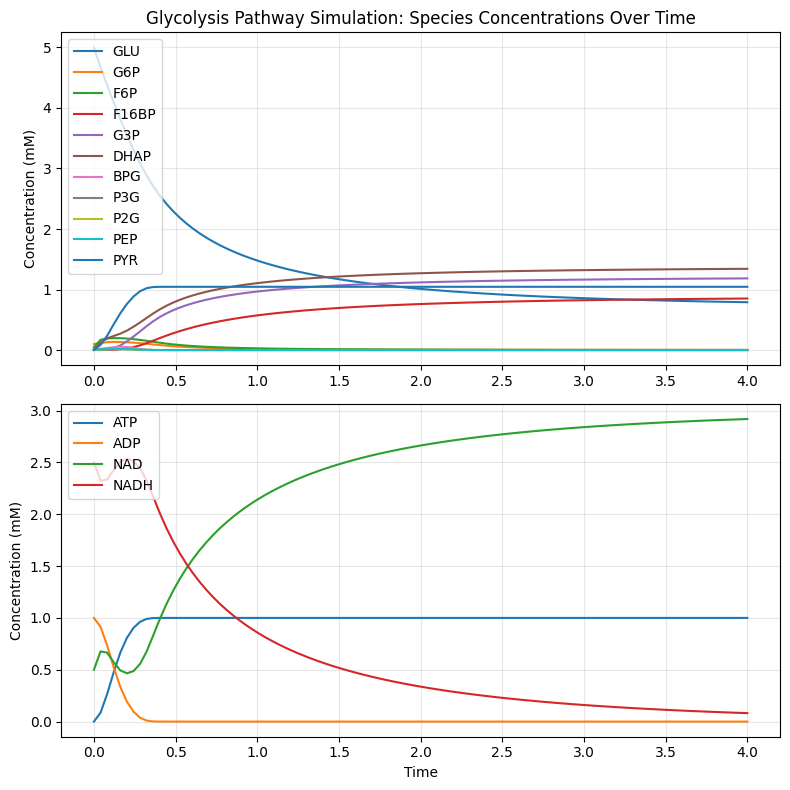

In [22]:
#The goal is to simulate the entire upper glycolysis cycle
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#Rate constants
k = {
        'HEX':  {'f': 0.70,   'r': 0.001},  # Step 1: Hexokinase (Highly exergonic/irreversible)
        'PGI':  {'f': 3600.0, 'r': 2400.0}, # Step 2: Phosphoglucose Isomerase
        'PFK':  {'f': 35.0,   'r': 0.005},  # Step 3: Phosphofructokinase (Irreversible commit)
        'ALD':  {'f': 2800.0, 'r': 1500.0}, # Step 4: Aldolase (F16BP -> G3P + DHAP)
        'TPI':  {'f': 34.0,   'r': 30.0},   # Step 5: Triose Phosphate Isomerase
        'GAPD': {'f': 3300.0, 'r': 2200.0}, # Step 6: GAPDH (G3P + NAD -> BPG + NADH)
        'PGK':  {'f': 1200.0, 'r': 800.0},  # Step 7: Phosphoglycerate Kinase
        'PGM':  {'f': 4800.0, 'r': 4000.0}, # Step 8: Phosphoglycerate Mutase
        'ENO':  {'f': 1700.0, 'r': 1200.0}, # Step 9: Enolase
        'PYK':  {'f': 450.0,  'r': 0.01},   # Step 10: Pyruvate Kinase (Irreversible)
        'ATPase':{'f': 0.1,    'r': 0.0}     # Homeostatic ATP consumption to simulate cell work

    }

def glycolysis(t, y):
  GLU, G6P, F6P, F16BP, G3P, DHAP, BPG, P3G, P2G, PEP, PYR, ATP, ADP, NAD, NADH = y #Species whose concentrations we want to track

  #Rate expressions
  v1 = k['HEX']['f']*GLU*ATP - k['HEX']['r'] * G6P*ADP
  v2 = k['PGI']['f']*G6P - k['PGI']['r']*F6P
  v3 = k['PFK']['f']*F6P - k['PFK']['r']*F16BP
  v4 = k['ALD']['f']*F16BP - k['ALD']['r']*G3P*DHAP
  v5 = k['TPI']['f']*G3P - k['TPI']['r']*DHAP
  v6 = k['GAPD']['f']*G3P*NAD - k['GAPD']['r']*BPG*NADH
  v7 = k['PGK']['f']*BPG*ADP - k['PGK']['r']*P3G*ATP
  v8 = k['PGM']['f']*P3G - k['PGM']['r']*P2G
  v9 = k['ENO']['f']*P2G - k['ENO']['r']*PEP
  v10 = k['PYK']['f']*PEP*ADP - k['PYK']['r']*PYR*ATP
  v_atp = k['ATPase']['f']*ATP #ATP sink - to account for all other ATP conversions

  dGLU = -v1
  dG6P = v1 - v2
  dF6P = v2 - v3
  dF16BP = v3 - v4
  dG3P = -v5 - v6
  dDHAP = v4 + v5
  dBPG = v6 - v7
  dP3G = v7 - v8
  dP2G = -v9 + v8
  dPEP = v9 - v10
  dPYR = v10

  dATP = - v1 + v7 + v10 - v_atp
  dADP = v1 - v7 - v10 + v_atp
  dNAD = -v6
  dNADH = v6

  return [dGLU, dG6P, dF6P, dF16BP, dG3P, dDHAP, dBPG, dP3G, dP2G, dPEP, dPYR, dATP, dADP, dNAD, dNADH]

initial_conc = [5, 0.1, 0.05, 0.01, 0.005, 0.005, 0.01, 0.02, 0.005, 0.01, 0, 2.5, 0.5, 1, 0]

sol = solve_ivp(glycolysis, t_span = (0, 4), y0 = initial_conc, t_eval = np.linspace(0, 4, 100), )

species = ['GLU', 'G6P', 'F6P', 'F16BP', 'G3P', 'DHAP', 'BPG', 'P3G', 'P2G', 'PEP', 'PYR']

plt.figure(figsize =(8, 8))
plt.subplot(2, 1, 1)
for i, name in enumerate(species):
  plt.plot(sol.t, sol.y[i], label = name)

plt.title('Glycolysis Pathway Simulation: Species Concentrations Over Time')
plt.ylabel('Concentration (mM)')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

species_cat = ['ATP', 'ADP', 'NAD', 'NADH']
plt.subplot(2, 1, 2)
for i, name in enumerate(species_cat):
  plt.plot(sol.t, sol.y[14-i], label = name)

plt.xlabel('Time')
plt.ylabel('Concentration (mM)')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()



